# Chapter 3 - Statistical Experiments and Significance Testing

**Practical Statistics for Data Scientists, 2nd ed.** - Peter Bruce, Andrew Bruce, and Peter Gedeck

This notebook implements an original A/B experiment and covers resampling, p-values, multiple tests, bandits, and power. All examples are locally simulated.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
rng = np.random.default_rng(42)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 3)

## 1. A/B testing and randomized assignment

An experiment changes one treatment and compares its outcome with a control. Random assignment makes groups comparable *on average*, reducing confounding. The estimand here is treatment conversion rate minus control conversion rate. The control provides a counterfactual baseline: what would likely happen without the change?

In [2]:
n_per_group = 2000
experiment = pd.DataFrame({
    "variant": np.repeat(["control", "treatment"], n_per_group),
    "converted": np.r_[rng.binomial(1, .110, n_per_group), rng.binomial(1, .124, n_per_group)],
})
rates = experiment.groupby("variant").converted.agg(["sum", "count", "mean"])
observed_diff = rates.loc["treatment", "mean"] - rates.loc["control", "mean"]
display(rates); print(f"Observed absolute lift: {observed_diff:.2%}")

,sum,count,mean
variant,,,
control,229,2000,0.115
treatment,245,2000,0.122


Observed absolute lift: 0.80%


## 2. Permutation test and p-value

Under a **null hypothesis** of no treatment effect, the outcome labels are exchangeable across treatment labels. A permutation test repeatedly breaks the treatment-outcome link, recomputes the statistic, and compares the observed statistic with this null distribution. The p-value is a measure of compatibility with the null model, not the probability that the null hypothesis is true.

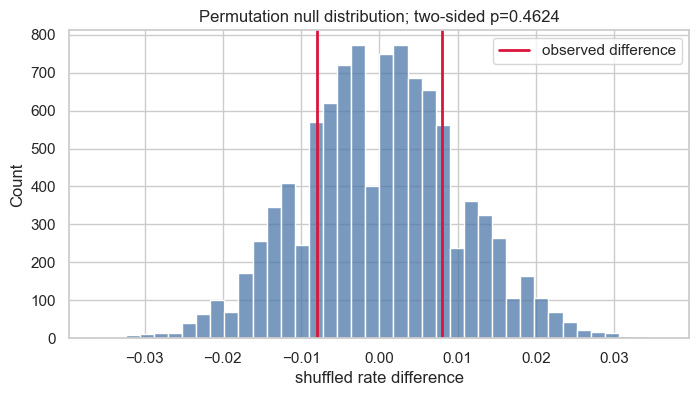

In [3]:
def permutation_differences(data, repetitions=10_000, seed=1):
    local_rng = np.random.default_rng(seed)
    outcome = data.converted.to_numpy(); control_size = (data.variant == "control").sum()
    differences = np.empty(repetitions)
    for i in range(repetitions):
        shuffled = local_rng.permutation(outcome)
        differences[i] = shuffled[control_size:].mean() - shuffled[:control_size].mean()
    return differences

null_diffs = permutation_differences(experiment)
p_perm = (np.abs(null_diffs) >= abs(observed_diff)).mean()
fig, ax = plt.subplots(figsize=(8, 4)); sns.histplot(null_diffs, bins=40, color="#4c78a8", ax=ax)
ax.axvline(observed_diff, color="crimson", lw=2, label="observed difference"); ax.axvline(-observed_diff, color="crimson", lw=2)
ax.set(title=f"Permutation null distribution; two-sided p={p_perm:.4f}", xlabel="shuffled rate difference"); ax.legend(); plt.show()

## 3. Formula tests, alpha, and errors

The **alpha** level is a decision threshold chosen before seeing results. A Type I error rejects a true null; a Type II error misses a real effect. Formula tests are efficient when their assumptions are reasonable. Fisher's exact test is particularly useful for small contingency tables, while the chi-square approximation is common with larger expected counts.

In [4]:
from scipy import stats
control = experiment.query("variant == 'control'").converted
treatment = experiment.query("variant == 'treatment'").converted
contingency = pd.crosstab(experiment.variant, experiment.converted)
t_stat, p_t = stats.ttest_ind(treatment, control, equal_var=False)
chi2, p_chi2, df, expected = stats.chi2_contingency(contingency)
odds_ratio, p_fisher = stats.fisher_exact(contingency)
pd.Series({"Welch t-test p-value": p_t, "chi-square p-value": p_chi2,
           "Fisher exact p-value": p_fisher, "chi-square statistic": chi2, "degrees of freedom": df})

Welch t-test p-value    0.434
chi-square p-value      0.463
Fisher exact p-value    0.463
chi-square statistic    0.538
degrees of freedom      1.000
dtype: float64

## 4. Multiple testing

With many independent tests at alpha = 0.05, false positives are expected. Bonferroni controls family-wise error by making each test stricter. Benjamini-Hochberg controls the expected false discovery rate (FDR). The test family must be specified honestly before inspecting the most favorable results.

In [5]:
from statsmodels.stats.multitest import multipletests
p_values = np.r_[.001, .018, rng.uniform(0, 1, 18)]
bonf = multipletests(p_values, alpha=.05, method="bonferroni")
fdr = multipletests(p_values, alpha=.05, method="fdr_bh")
pd.DataFrame({"metric": [f"metric_{i+1}" for i in range(20)], "raw p": p_values,
              "Bonferroni p": bonf[1], "BH-FDR p": fdr[1],
              "reject Bonferroni": bonf[0], "reject BH-FDR": fdr[0]}).round(4)

,metric,raw p,Bonferroni p,BH-FDR p,reject Bonferroni,reject BH-FDR
0,metric_1,0.001,0.02,0.020,True,True
1,metric_2,0.018,0.36,0.180,False,False
2,metric_3,0.716,1.00,0.796,False,False
3,metric_4,0.357,1.00,0.649,False,False
4,metric_5,0.852,1.00,0.897,False,False
5,metric_6,0.241,1.00,0.528,False,False
6,metric_7,0.538,1.00,0.706,False,False
7,metric_8,0.184,1.00,0.526,False,False
8,metric_9,0.495,1.00,0.706,False,False
9,metric_10,0.152,1.00,0.526,False,False


## 5. Multi-arm bandit

Traditional A/B tests usually use a fixed allocation. A bandit adapts as outcomes arrive, balancing **exploration** of uncertain arms against **exploitation** of the arm that currently looks best. Thompson sampling uses beta distributions to represent uncertainty about binary conversion rates.

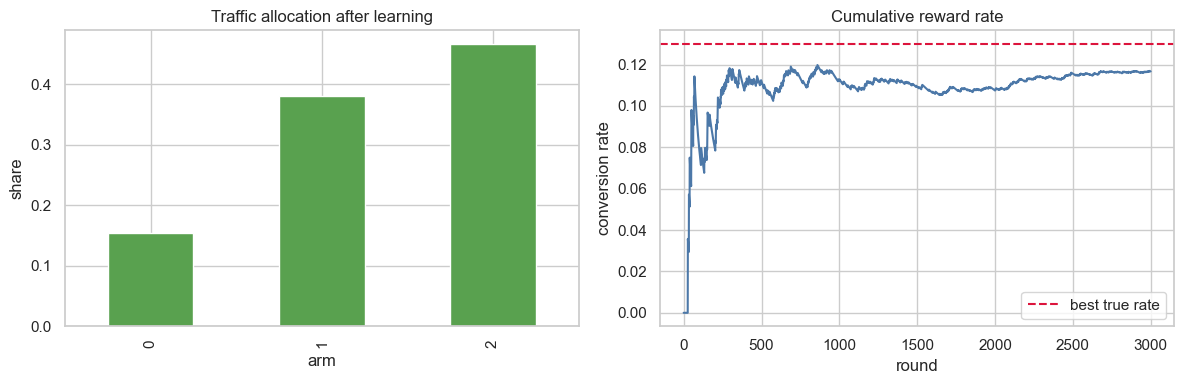

In [6]:
def thompson_bandit(true_rates, rounds=3000, seed=4):
    local_rng = np.random.default_rng(seed); alpha = np.ones(len(true_rates)); beta = np.ones(len(true_rates))
    choices, rewards = [], []
    for _ in range(rounds):
        arm = np.argmax(local_rng.beta(alpha, beta)); reward = local_rng.binomial(1, true_rates[arm])
        alpha[arm] += reward; beta[arm] += 1-reward; choices.append(arm); rewards.append(reward)
    return np.array(choices), np.array(rewards)

choices, rewards = thompson_bandit([.09, .11, .13])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
pd.Series(choices).value_counts(normalize=True).sort_index().plot.bar(color="#59a14f", ax=axes[0])
axes[0].set(title="Traffic allocation after learning", xlabel="arm", ylabel="share")
axes[1].plot(np.cumsum(rewards)/np.arange(1, len(rewards)+1), color="#4c78a8")
axes[1].axhline(.13, color="crimson", ls="--", label="best true rate")
axes[1].set(title="Cumulative reward rate", xlabel="round", ylabel="conversion rate"); axes[1].legend(); plt.tight_layout()

## 6. Power and sample size

**Power** is the probability that a planned test detects a specified real effect. It depends on effect size, sample size, alpha, and variability. Pre-study planning prevents a costly experiment that has little chance to resolve the decision.

In [7]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
baseline, target = .110, .124
effect = proportion_effectsize(target, baseline)
analysis = NormalIndPower()
needed = analysis.solve_power(effect_size=effect, alpha=.05, power=.80, ratio=1, alternative="two-sided")
achieved = analysis.power(effect_size=effect, nobs1=n_per_group, alpha=.05, ratio=1, alternative="two-sided")
print(f"Effect to detect: {target-baseline:.1%} absolute lift")
print(f"Required observations per group for 80% power: {np.ceil(needed):,.0f}")
print(f"Approximate power of this design: {achieved:.1%}")

Effect to detect: 1.4% absolute lift
Required observations per group for 80% power: 8,268
Approximate power of this design: 28.1%


## Chapter 3 summary

- Randomized control groups support credible causal comparisons.
- Permutation tests build a transparent null reference by shuffling treatment labels.
- A p-value is not practical importance or the probability a hypothesis is true.
- Account for all planned comparisons, and plan sample size from a meaningful effect.

**Reference:** Bruce, P., Bruce, A., & Gedeck, P. (2020). *Practical Statistics for Data Scientists* (2nd ed.), Chapter 3. Concepts and organization informed by the supplied PDF; all prose, code, and synthetic data here are original.